# 실습문제 5번

모델 선언 및 학습 관련 코드로 ipynb 파일이 과도하게 길어져서 모듈화를 진행함

- 모델 파일 : net.py
- 파라미터 등 설정 파일 : config.py
- 가상환경 생성 및 사전 설정 파일 : build.py
- 실험 구성 및 설정 파일 : experiments.py
- ch10_수업에서 가져온 fit, history 등 util 함수 : utils.py
- 학습 관련 코드 : train.py

In [4]:
"""
실험 2: CNN_v2 + Momentum
실험 3: CNN_v2 + Adam
실험 4: CNN_v3
실험 5: CNN_v4
실험 6: CNN_v4 + data augmentation(RandomHorizontalFlip, RandomErasing)
"""
import train
train.main(["--list"])

1: Experiment 1: CNN_v2 (model=CNN_v2, epochs=30, batch_size=100, optimizer=sgd(lr=0.01))
2: Experiment 2: CNN_v2 (model=CNN_v2, epochs=30, batch_size=100, optimizer=sgd(lr=0.01, momentum=0.9))
3: Experiment 3: CNN_v2 (model=CNN_v2, epochs=30, batch_size=100, optimizer=adam(lr=0.001))
4: Experiment 4: CNN_v3 (model=CNN_v3, epochs=30, batch_size=100, optimizer=adam(lr=0.001))
5: Experiment 5: CNN_v4 (model=CNN_v4, epochs=30, batch_size=100, optimizer=adam(lr=0.001))
6: Experiment 6: CNN_v4 + augmentation (model=CNN_v4, epochs=30, batch_size=100, optimizer=adam(lr=0.001))


In [ ]:
# all 인자 입력시 모든 실험을 진행함.
# 출력이 너무 길어져서 따로 정리한 사진 첨부
train.main(['all'])

# 실습문제 5번 결과

![실습문제 5번 결과](experiments.png)

# 실습문제 6번

In [ ]:
import train
train.main(["--epochs 100", "7"])

# 실습문제 7번

- 정확히 예측한 모습을 확인할 수 있다.

pred: cat, ground_truth: cat


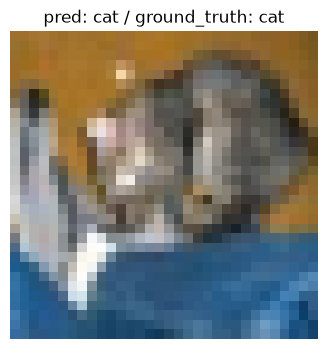

In [13]:
import matplotlib.pyplot as plt
import torch
from torchvision import datasets

from config import CONFIG, get_device
from experiments import EXPERIMENTS

experiment = EXPERIMENTS[5]
device = get_device()

test_set = datasets.CIFAR10(root=str(CONFIG.data_dir), train=False, download=False,
                            transform=experiment.test_transform())
classes = test_set.classes

net = experiment.model(len(classes)).to(device)
state_dict = torch.load(f"./ckpts/{experiment.key}/model_final.pth", map_location=device)
net.load_state_dict(state_dict)
net.eval()

image, label = test_set[0]
with torch.no_grad():
    output = net(image.unsqueeze(0).to(device))
pred = output.argmax(dim=1).item()

print(f"pred: {classes[pred]}, ground_truth: {classes[label]}")

plt.figure(figsize=(4, 4))
plt.imshow((image * 0.5 + 0.5).permute(1, 2, 0).numpy())
plt.title(f"pred: {classes[pred]} / ground_truth: {classes[label]}")
plt.axis("off")
plt.show()